In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style('whitegrid')
sns.set_palette('pastel')

In [2]:
df_tea = pd.read_csv('student_tea_snacks _1_.csv')

In [3]:
print("Shape:", df_tea.shape)
print("Columns:", df_tea.columns.tolist())
print("\nHead:\n", df_tea.head(10))
print("\nInfo:")
df_tea.info()
print("\nDescribe:\n", df_tea.describe(include='all'))
print("\nMissing values:\n", df_tea.isnull().sum())

Shape: (100, 7)
Columns: ['student_id', 'gender', 'age_group', 'prefers_tea', 'tea_type', 'snack_choice', 'cups_per_day']

Head:
   student_id  gender age_group prefers_tea     tea_type snack_choice  \
0       S001    Male     21-23          No        Black       Samosa   
1       S002    Male     21-23          No        Green       Samosa   
2       S003    Male     18-20          No  Doodh Patti      Biscuit   
3       S004    Male     21-23         Yes          NaN       Samosa   
4       S005    Male     18-20         Yes        Green       Samosa   
5       S006  Female     18-20         Yes        Black        Chips   
6       S007    Male     24-26          No        Green        Chips   
7       S008    Male     18-20         Yes        Black        Chips   
8       S009  Female     18-20          No        Green      Biscuit   
9       S010  Female     21-23         Yes          NaN       Samosa   

   cups_per_day  
0             2  
1             3  
2             0  
3    

In [4]:
print("\nUnique values per column:")
for c in df_tea.columns:
    print(f"--- {c} ---")
    print(df_tea[c].value_counts(dropna=False))


Unique values per column:
--- student_id ---
student_id
S001    1
S002    1
S003    1
S004    1
S005    1
       ..
S096    1
S097    1
S098    1
S099    1
S100    1
Name: count, Length: 100, dtype: int64
--- gender ---
gender
Male      53
Female    47
Name: count, dtype: int64
--- age_group ---
age_group
18-20    39
21-23    32
24-26    29
Name: count, dtype: int64
--- prefers_tea ---
prefers_tea
Yes    51
No     49
Name: count, dtype: int64
--- tea_type ---
tea_type
Green          29
Doodh Patti    25
Black          23
NaN            23
Name: count, dtype: int64
--- snack_choice ---
snack_choice
Samosa     40
Chips      31
Biscuit    29
Name: count, dtype: int64
--- cups_per_day ---
cups_per_day
3    22
5    21
4    17
2    15
0    13
1    12
Name: count, dtype: int64


In [5]:
# Q1: What is the most preferred tea type?
tea_type_counts = df_tea['tea_type'].value_counts()
print("Q1 - tea_type counts (non-null):")
print(tea_type_counts)
print("Most preferred tea type:", tea_type_counts.index[0], "with", tea_type_counts.iloc[0], "responses")

Q1 - tea_type counts (non-null):
tea_type
Green          29
Doodh Patti    25
Black          23
Name: count, dtype: int64
Most preferred tea type: Green with 29 responses


In [6]:
# Q2: What is the average number of cups per gender?
cups_by_gender = df_tea.groupby('gender')['cups_per_day'].agg(['count', 'mean', 'median', 'std', 'min', 'max'])
print("\nQ2 - cups_per_day by gender:")
print(cups_by_gender)


Q2 - cups_per_day by gender:
        count      mean  median       std  min  max
gender                                             
Female     47  2.595745     3.0  1.752757    0    5
Male       53  3.000000     3.0  1.593255    0    5



Q3 - snack_choice counts:
snack_choice
Samosa     40
Chips      31
Biscuit    29
Name: count, dtype: int64


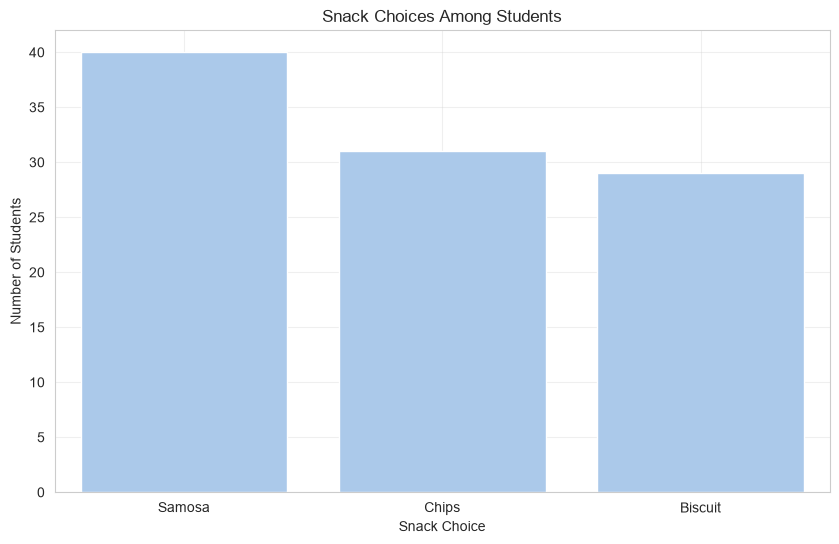

In [7]:
# Q3: Make a bar chart of snack choices.
snack_counts = df_tea['snack_choice'].value_counts()
print("\nQ3 - snack_choice counts:")
print(snack_counts)
plt.figure(figsize=(10, 6))
sns.barplot(x=snack_counts.index, y=snack_counts.values)
plt.title('Snack Choices Among Students')
plt.xlabel('Snack Choice')
plt.ylabel('Number of Students')
plt.grid(True, alpha=0.3)
plt.savefig('q3_snack_choices.png', dpi=300, bbox_inches='tight')
plt.show()

In [8]:
# Q4: Compare tea preference by age group.
age_tea_ct = pd.crosstab(df_tea['age_group'], df_tea['prefers_tea'], margins=True)
age_tea_pct = pd.crosstab(df_tea['age_group'], df_tea['prefers_tea'], normalize='index') * 100
age_tea_type = pd.crosstab(df_tea['age_group'], df_tea['tea_type'].fillna('Unspecified'))
print("\nQ4 - prefers_tea by age_group (counts):")
print(age_tea_ct)
print("\nQ4 - prefers_tea by age_group (% within age group):")
print(age_tea_pct.round(2))
print("\nQ4 - tea_type by age_group (counts):")
print(age_tea_type)


Q4 - prefers_tea by age_group (counts):
prefers_tea  No  Yes  All
age_group                
18-20        19   20   39
21-23        17   15   32
24-26        13   16   29
All          49   51  100

Q4 - prefers_tea by age_group (% within age group):
prefers_tea     No    Yes
age_group                
18-20        48.72  51.28
21-23        53.12  46.88
24-26        44.83  55.17

Q4 - tea_type by age_group (counts):
tea_type   Black  Doodh Patti  Green  Unspecified
age_group                                        
18-20          9           11     13            6
21-23          9            6      5           12
24-26          5            8     11            5


In [10]:
# Q5: Count the number of students who don't drink tea.
no_tea_pref_count = (df_tea['prefers_tea'] == 'No').sum()
zero_cups_count = (df_tea['cups_per_day'] == 0).sum()
both_no_pref_zero_cups = ((df_tea['prefers_tea'] == 'No') & (df_tea['cups_per_day'] == 0)).sum()
print(f"\nQ5 - prefers_tea == 'No': {no_tea_pref_count}")
print(f"Q5 - cups_per_day == 0: {zero_cups_count}")
print(f"Q5 - Both prefers_tea == 'No' and cups_per_day == 0: {both_no_pref_zero_cups}")


Q5 - prefers_tea == 'No': 49
Q5 - cups_per_day == 0: 13
Q5 - Both prefers_tea == 'No' and cups_per_day == 0: 8
